In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kaggle

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token


In [2]:
%env KAGGLE_API_TOKEN=KGAT_ad0cfeb24599b0621d0eec44ad7ddd80
kaggle.api.authenticate()
kaggle.api.dataset_download_files('yasserh/titanic-dataset', path='.', unzip=True)

env: KAGGLE_API_TOKEN=KGAT_ad0cfeb24599b0621d0eec44ad7ddd80
Dataset URL: https://www.kaggle.com/datasets/yasserh/titanic-dataset


In [3]:
df = pd.read_csv('Titanic-Dataset.csv', sep=',')
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [4]:
print("ИЗУЧЕНИЕ ПРИЗНАКОВ И ИХ ТИПОВ")
print(f"Размерность датасета: {df.shape[0]} строк, {df.shape[1]} колонок\n")
print(df.info())

print("ПОИСК ПРОПУСКОВ")
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_table = pd.concat([missing_data, missing_percent], axis=1, keys=['Количество пропусков', '% пропусков'])
print(missing_table[missing_table['Количество пропусков'] > 0])

print("ПОИСК ДУБЛИКАТОВ")
duplicates_count = df.duplicated().sum()
print(f"Количество полных дубликатов строк в датасете: {duplicates_count}")

print("РАСПРЕДЕЛЕНИЕ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ")
target_counts = df['Survived'].value_counts()
target_percent = df['Survived'].value_counts(normalize=True) * 100
target_table = pd.concat([target_counts, target_percent], axis=1, keys=['Количество', '%'])
target_table.index = target_table.index.map({0: '0 (Погибли)', 1: '1 (Выжили)'})
print(target_table)

print("СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ")
print(df.describe())


ИЗУЧЕНИЕ ПРИЗНАКОВ И ИХ ТИПОВ
Размерность датасета: 891 строк, 12 колонок

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None
ПОИСК ПРОПУСКОВ
          Количество пропусков  % пропусков
Age                        177    19.865320
Cabin                      687    77.104377
Embarked        

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=['PassengerId', 'Survived', 'Name', 'Ticket', 'Cabin'])

num = ["Age", "Fare", "SibSp", "Parch"]
cat = ["Pclass", "Sex", "Embarked"]

preprocess_tree = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), num),
    
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)) 
    ]), cat)
])

preprocess_scaled = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num),
    
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)) 
    ]), cat)
])


X_ready = preprocess_tree.fit_transform(X)

print("Размер исходных данных X_train:", X.shape)
print("Размер обработанных данных X_ready:", X_ready.shape)

Размер исходных данных X_train: (891, 7)
Размер обработанных данных X_ready: (891, 12)


In [6]:
from sklearn.model_selection import train_test_split

y = df['Survived']
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_scaled = preprocess_scaled.fit_transform(X_train_raw)
X_test_scaled = preprocess_scaled.transform(X_test_raw)

X_train_tree = preprocess_tree.fit_transform(X_train_raw)
X_test_tree = preprocess_tree.transform(X_test_raw)

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train_scaled, y_train)
pred = baseline.predict(X_test_scaled)

print("Accuracy:",  accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, zero_division=0))
print("Recall:",    recall_score(y_test, pred))
print("F1:",        f1_score(y_test, pred))

Accuracy: 0.5865921787709497
Precision: 0.0
Recall: 0.0
F1: 0.0


In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

tree = Pipeline([
    ("prep", preprocess_tree),
    ("model", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    )) 
])

tree.fit(X_train_raw, y_train)

pred = tree.predict(X_test_raw)

print("Accuracy: ", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall:   ", recall_score(y_test, pred))
print("F1: ", f1_score(y_test, pred))

Accuracy:  0.7988826815642458
Precision: 0.8392857142857143
Recall:    0.6351351351351351
F1-Score:  0.7230769230769231


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.pipeline import Pipeline

rf = Pipeline([
    ("prep", preprocess_tree),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf.fit(X_train_raw, y_train)
pred_rf = rf.predict(X_test_raw)

print(f"Accuracy:  {accuracy_score(y_test, pred_rf):.3f}")
print(f"Precision: {precision_score(y_test, pred_rf):.3f}")
print(f"Recall:    {recall_score(y_test, pred_rf):.3f}")
print(f"F1:        {f1_score(y_test, pred_rf):.3f}")
print("CM:", confusion_matrix(y_test, pred_rf).tolist())

Accuracy:  0.849
Precision: 0.862
Recall:    0.757
F1:        0.806
CM: [[96, 9], [18, 56]]


In [10]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.pipeline import Pipeline

gb = Pipeline([
    ("prep", preprocess_tree),
    ("model", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])

gb.fit(X_train_raw, y_train)
pred_gb = gb.predict(X_test_raw)

print(f"Accuracy:  {accuracy_score(y_test, pred_gb):.3f}")
print(f"Precision: {precision_score(y_test, pred_gb):.3f}")
print(f"Recall:    {recall_score(y_test, pred_gb):.3f}")
print(f"F1:        {f1_score(y_test, pred_gb):.3f}")
print("CM:", confusion_matrix(y_test, pred_gb).tolist())

Accuracy:  0.804
Precision: 0.800
Recall:    0.703
F1:        0.748
CM: [[92, 13], [22, 52]]


In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

svm = Pipeline([
    ("prep", preprocess_scaled),
    ("model", SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        probability=True
    ))
])

svm.fit(X_train_raw, y_train)
pred_svm = svm.predict(X_test_raw)

print(f"Accuracy:  {accuracy_score(y_test, pred_svm):.3f}")
print(f"Precision: {precision_score(y_test, pred_svm):.3f}")
print(f"Recall:    {recall_score(y_test, pred_svm):.3f}")
print(f"F1:        {f1_score(y_test, pred_svm):.3f}")
print("CM:", confusion_matrix(y_test, pred_svm).tolist())

Accuracy:  0.816
Precision: 0.806
Recall:    0.730
F1:        0.766
CM: [[92, 13], [20, 54]]


In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

knn = Pipeline([
    ("prep", preprocess_scaled),
    ("model", KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    ))
])

knn.fit(X_train_raw, y_train)
pred_knn = knn.predict(X_test_raw)

print(f"Accuracy:  {accuracy_score(y_test, pred_knn):.3f}")
print(f"Precision: {precision_score(y_test, pred_knn):.3f}")
print(f"Recall:    {recall_score(y_test, pred_knn):.3f}")
print(f"F1:        {f1_score(y_test, pred_knn):.3f}")
print("CM:", confusion_matrix(y_test, pred_knn).tolist())

Accuracy:  0.793
Precision: 0.753
Recall:    0.743
F1:        0.748
CM: [[87, 18], [19, 55]]


In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Baseline": baseline,
    "Decision Tree": tree,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "SVM": svm,
    "KNN": knn
}

rows = []

for name, model in models.items():
    model.fit(X_train_raw, y_train)
    pred = model.predict(X_test_raw)
    
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Precision": round(precision_score(y_test, pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, pred), 4),
        "F1-Score": round(f1_score(y_test, pred), 4)
    })

results = pd.DataFrame(rows).sort_values("F1-Score", ascending=False)
display(results)


,Model,Accuracy,Precision,Recall,F1-Score
2,Random Forest,0.8492,0.8615,0.7568,0.8058
4,SVM,0.8156,0.8060,0.7297,0.7660
5,KNN,0.7933,0.7534,0.7432,0.7483
3,Gradient Boosting,0.8045,0.8000,0.7027,0.7482
1,Decision Tree,0.7989,0.8393,0.6351,0.7231
0,Baseline,0.5866,0.0000,0.0000,0.0000


,Model,Accuracy,Precision,Recall,F1-Score
2,Random Forest,0.8492,0.8615,0.7568,0.8058
4,SVM,0.8156,0.8060,0.7297,0.7660
5,KNN,0.7933,0.7534,0.7432,0.7483
3,Gradient Boosting,0.8045,0.8000,0.7027,0.7482
1,Decision Tree,0.7989,0.8393,0.6351,0.7231
0,Baseline,0.5866,0.0000,0.0000,0.0000


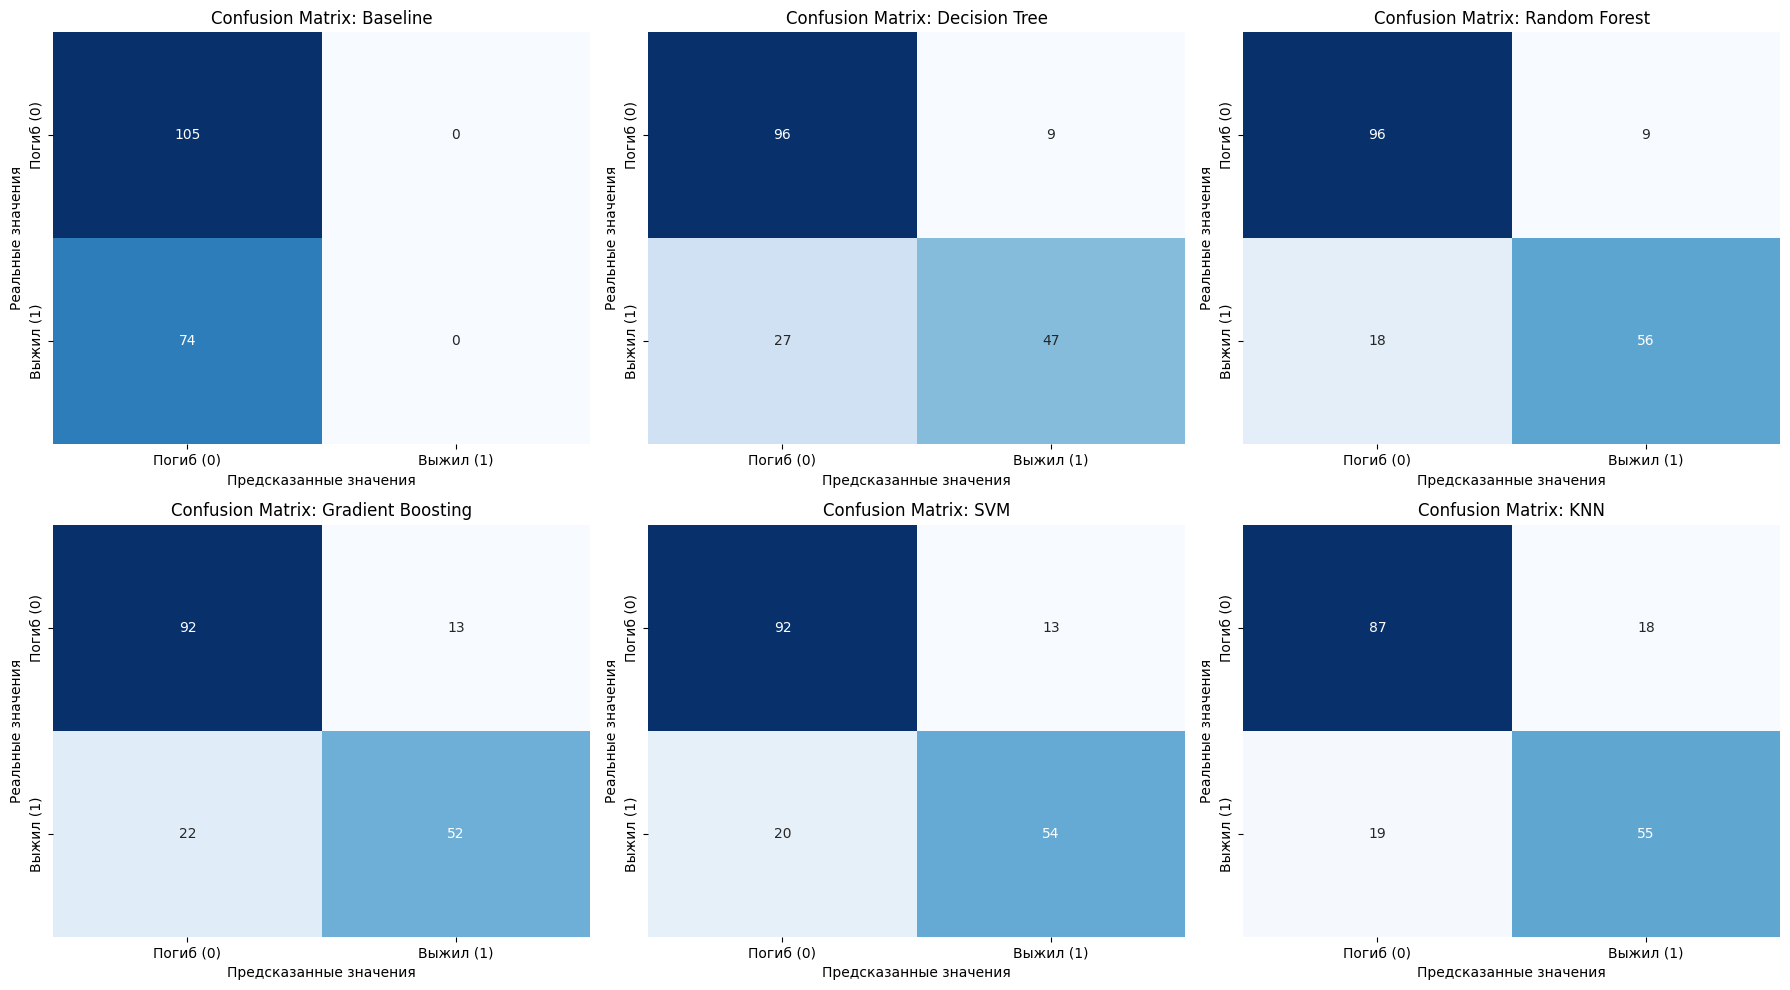

In [15]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

models = {
    "Baseline": baseline,
    "Decision Tree": tree,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "SVM": svm,
    "KNN": knn,
}

rows = []

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_train_raw, y_train)
    pred = model.predict(X_test_raw)

    rows.append(
        {
            "Model": name,
            "Accuracy": round(accuracy_score(y_test, pred), 4),
            "Precision": round(
                precision_score(y_test, pred, zero_division=0), 4
            ),
            "Recall": round(recall_score(y_test, pred), 4),
            "F1-Score": round(f1_score(y_test, pred), 4),
        }
    )

    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i],
        cbar=False,
        xticklabels=["Погиб (0)", "Выжил (1)"],
        yticklabels=["Погиб (0)", "Выжил (1)"],
    )
    axes[i].set_title(f"Confusion Matrix: {name}")
    axes[i].set_ylabel("Реальные значения")
    axes[i].set_xlabel("Предсказанные значения")

results = pd.DataFrame(rows).sort_values("F1-Score", ascending=False)
display(results)

plt.tight_layout()
plt.show()

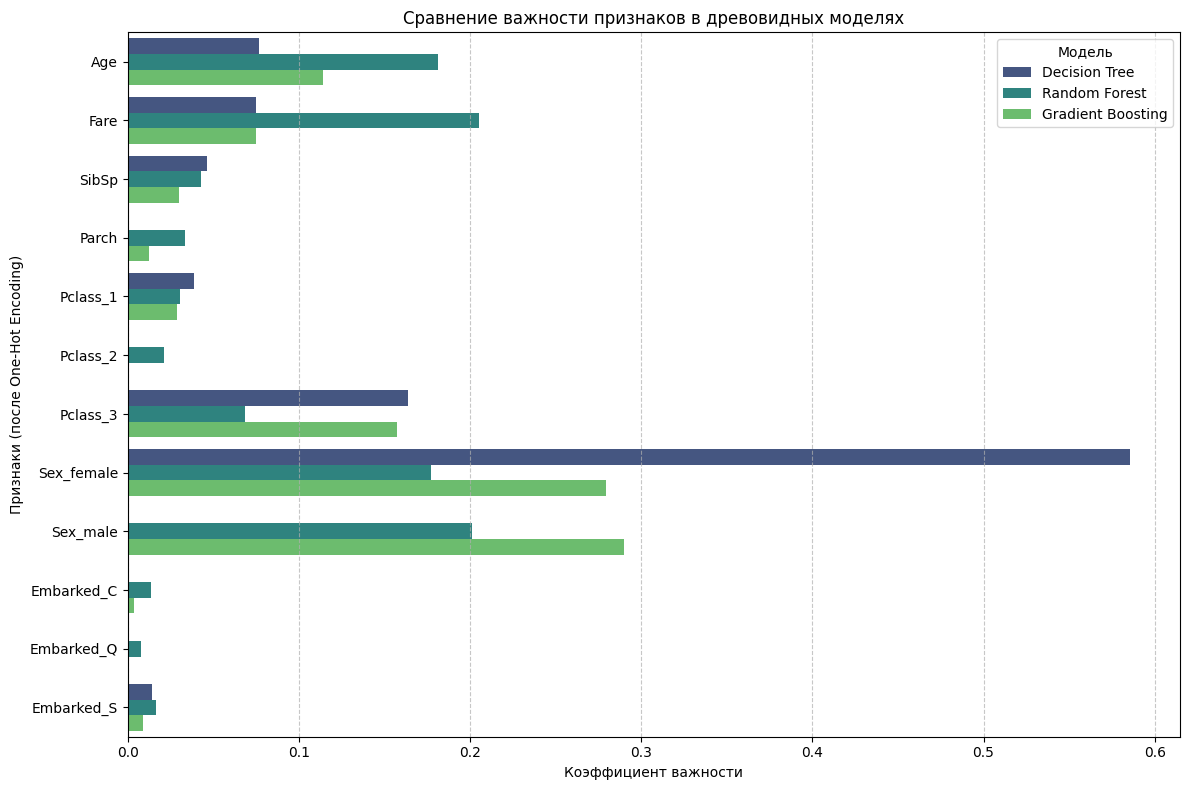

In [16]:
feature_names = (
    num
    + tree.named_steps["prep"]
    .named_transformers_["cat"]
    .named_steps["ohe"]
    .get_feature_names_out(cat)
    .tolist()
)

dt_importances = tree.named_steps["model"].feature_importances_
rf_importances = rf.named_steps["model"].feature_importances_
gb_importances = gb.named_steps["model"].feature_importances_

importance_df = pd.DataFrame(
    {
        "Признак": feature_names * 3,
        "Важность": np.concatenate(
            [dt_importances, rf_importances, gb_importances]
        ),
        "Модель": ["Decision Tree"] * len(feature_names)
        + ["Random Forest"] * len(feature_names)
        + ["Gradient Boosting"] * len(feature_names),
    }
)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=importance_df,
    x="Важность",
    y="Признак",
    hue="Model" if "Model" in importance_df.columns else "Модель",
    palette="viridis",
)
plt.title("Сравнение важности признаков в древовидных моделях")
plt.xlabel("Коэффициент важности")
plt.ylabel("Признаки (после One-Hot Encoding)")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [17]:
pred_rf = rf.predict(X_test_raw)

analysis_df = X_test_raw.copy()
analysis_df["Real_Survived"] = y_test
analysis_df["Pred_Survived"] = pred_rf

analysis_df["Name"] = df.loc[analysis_df.index, "Name"]
analysis_df["Cabin"] = df.loc[analysis_df.index, "Cabin"]

false_positives = analysis_df[
    (analysis_df["Real_Survived"] == 0) & (analysis_df["Pred_Survived"] == 1)
]
false_negatives = analysis_df[
    (analysis_df["Real_Survived"] == 1) & (analysis_df["Pred_Survived"] == 0)
]

print(f"Ложноположительные FP: {len(false_positives)}")
print(f"Ложноотрицательные FN: {len(false_negatives)}")

print("\nПримеры Ложных Выживших (Модель думала, что выживет, но пассажир погиб):")
display(
    false_positives[["Name", "Sex", "Age", "Pclass", "Fare", "Embarked"]].head(
        3
    )
)

print("\nПримеры Ложных Погибших (Модель думала, что погибнет, но пассажир выжил):")
display(
    false_negatives[["Name", "Sex", "Age", "Pclass", "Fare", "Embarked"]].head(
        3
    )
)


Ложноположительные FP: 9
Ложноотрицательные FN: 18

Примеры Ложных Выживших (Модель думала, что выживет, но пассажир погиб):


,Name,Sex,Age,Pclass,Fare,Embarked
235,"Harknett, Miss. Alice Phoebe",female,NaN,3,7.55,S
772,"Mack, Mrs. (Mary)",female,57.0,2,10.50,S
312,"Lahtinen, Mrs. William (Anna Sylfven)",female,26.0,2,26.00,S



Примеры Ложных Погибших (Модель думала, что погибнет, но пассажир выжил):


,Name,Sex,Age,Pclass,Fare,Embarked
709,"Moubarek, Master. Halim Gonios (""William George"")",male,NaN,3,15.2458,C
39,"Nicola-Yarred, Miss. Jamila",female,14.0,3,11.2417,C
621,"Kimball, Mr. Edwin Nelson Jr",male,42.0,1,52.5542,S


# ДАЛЕЕ ДЛЯ KAGGLE

In [18]:
test_df = pd.read_csv('test.csv', sep=',')

print(test_df.head())

         Id  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0  55586928       3    male  25.0      0      0   9.1133        S
1  24554381       2    male  18.0      1      0  73.5000        S
2  50120493       3  female   NaN      0      2  17.4550        C
3  16342593       3    male  32.0      1      1   8.9682        S
4  10829305       3    male  50.0      0      0   7.0500        S


In [23]:
test_preds = rf.predict(test_df)

submission = pd.DataFrame({
    "Id": test_df["Id"],
    "Survived": test_preds
})

submission.to_csv('my_submission.csv', index=False)